In [6]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph
from langgraph.graph import START
from langgraph.graph import END
from langgraph.graph.message import add_messages
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

In [11]:
from langchain_google_genai import ChatGoogleGenerativeAI

c:\Users\emon1\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from dotenv import load_dotenv

load_dotenv()

True

In [4]:
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

In [7]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages: Annotated[list, add_messages]

In [9]:
@tool
def get_stock_price(symbol: str) -> float:
    '''Return the current price of a stock given the stock symbol
    :param symbol: stock symbol
    :return: current price of the stock
    '''
    return {
        "MSFT": 200.3,
        "AAPL": 100.4,
        "AMZN": 150.0,
        "RIL": 87.6
    }.get(symbol, 0.0)
    
tools = [get_stock_price]

In [12]:
llm = ChatGoogleGenerativeAI(model="gemini-2.0-flash")

llm_with_tools = llm.bind_tools(tools)

In [13]:
def chatbot(state: State):
    return {'messages':[llm_with_tools.invoke(state['messages'])]}

builder = StateGraph(State)

builder.add_node(chatbot)
builder.add_node('tools',ToolNode(tools))

builder.add_edge(START,'chatbot')
builder.add_conditional_edges('chatbot',tools_condition)
builder.add_edge('tools','chatbot')

graph = builder.compile(checkpointer=memory)

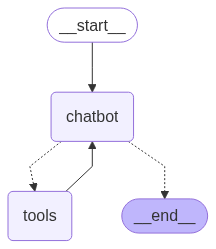

In [15]:
from IPython.display import Image
from IPython.display import display

display(Image(graph.get_graph().draw_mermaid_png()))

In [16]:
config1 = { 'configurable': { 'thread_id': '1'} }

msg = "I want to buy 20 AMZN stocks using current price. Then 15 MSFT. What will be the total cost?"

state = graph.invoke({"messages": [{"role": "user", "content": msg}]}, config=config1)
print(state["messages"][-1].content)

The current price for AMZN is $150 and for MSFT is $200.3.
The total cost for 20 AMZN stocks is 20 * $150 = $3000.
The total cost for 15 MSFT stocks is 15 * $200.3 = $3004.5.
Therefore, the total cost for both is $3000 + $3004.5 = $6004.5.


In [17]:
config2 = { 'configurable': { 'thread_id': '2'} }

msg = "Tell me the current price of 5 AAPL stocks."

state = graph.invoke({"messages": [{"role": "user", "content": msg}]}, config=config2)
print(state["messages"][-1].content)

The current price of one AAPL stock is $100.4. Therefore, the current price of 5 AAPL stocks is $502.


In [18]:
msg = "Using the current price tell me the total price of 10 RIL stocks and add it to previous total cost"

state = graph.invoke({"messages": [{"role": "user", "content": msg}]}, config=config1)
print(state["messages"][-1].content)

The current price for RIL is $87.6.
The total cost for 10 RIL stocks is 10 * $87.6 = $876.
Previous total cost was $6004.5.
Therefore, the new total cost is $6004.5 + $876 = $6880.5.


In [19]:
msg = "Tell me the current price of 5 MSFT stocks and add it to previous total"

state = graph.invoke({"messages": [{"role": "user", "content": msg}]}, config=config2)
print(state["messages"][-1].content)

The current price of one MSFT stock is $200.3. Therefore, the current price of 5 MSFT stocks is $1001. Adding that to the previous total of $502, the new total is $1503.
